# ReservoirScope – IND320 Compulsory Assignment Part 3

This notebook documents Part 3 of the ReservoirScope project.

The work focuses on:

- geographical reservoir regions from NVE shapefiles,
- random sampling of locations within each region,
- historical ERA5 weather data from the Open-Meteo API,
- precipitation outlier detection using DCT and Statistical Process Control,
- temperature anomaly detection using Local Outlier Factor,
- STL decomposition of reservoir filling levels,
- spectrogram analysis,
- and integration of these analyses into the Streamlit application.

In [83]:
# Import libraries for geographical data handling,
# numerical analysis, plotting, and file inspection.
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [84]:
# Define the folder containing the downloaded NVE shapefiles
# and inspect the available files before loading the geographical data.
shapefile_dir = Path("../data/shapefiles")

files = list(shapefile_dir.rglob("*"))

for file in files:
    print(file)

../data/shapefiles/elspotomraader.geojson
../data/shapefiles/nve_regions.geojson


In [85]:
# Identify all shapefile layers available in the NVE data folder.
shp_files = list(
    shapefile_dir.rglob("*.shp")
)

print("Number of shapefiles:", len(shp_files))

for file in shp_files:
    print(file)

Number of shapefiles: 0


In [86]:
# Load the NVE electricity bidding-area polygons.
elspot_path = shapefile_dir / "elspotomraader.geojson"

elspot_gdf = gpd.read_file(elspot_path)

print("Columns:")
print(elspot_gdf.columns)

print("\nCRS:")
print(elspot_gdf.crs)

print("\nElectricity areas:")
print(
    sorted(
        elspot_gdf["ElSpotOmr"]
        .dropna()
        .unique()
    )
)

Columns:
Index(['OBJECTID', 'ElSpotOmr', 'GlobalID', 'ORIG_FID', 'Shape.STArea()',
       'Shape.STLength()', 'geometry'],
      dtype='str')

CRS:
EPSG:4326

Electricity areas:
['NO1', 'NO2', 'NO3', 'NO4', 'NO5']


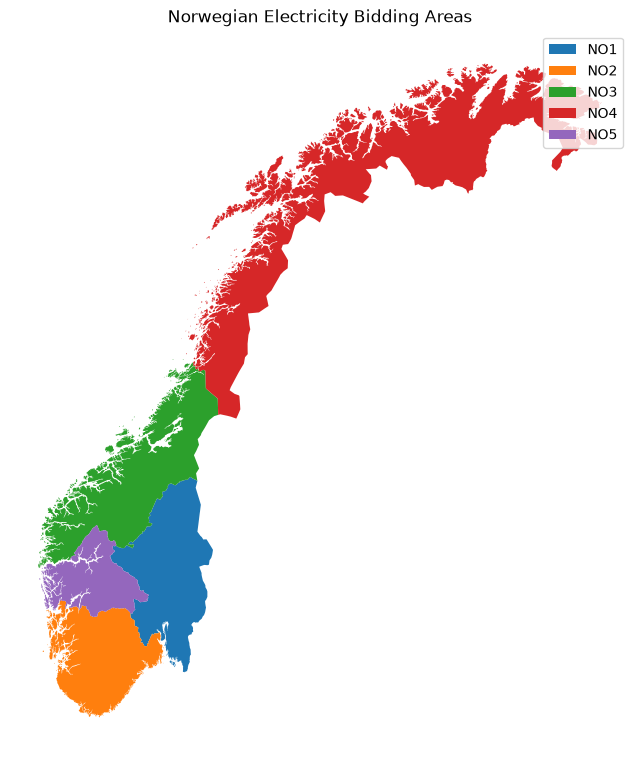

In [87]:
# Plot the electricity bidding areas to verify that
# the downloaded NVE polygons were loaded correctly.
elspot_gdf.plot(
    column="ElSpotOmr",
    legend=True,
    figsize=(8, 10)
)

plt.title("Norwegian Electricity Bidding Areas")
plt.axis("off")
plt.show()

## Geographical Regions for Weather Sampling

The Part 3 assignment requires weather data to be sampled from geographical
regions corresponding to the Magasinstatistikk areas.

Two types of regions are relevant:

- electricity bidding areas, such as NO1–NO5,
- precipitation/reservoir regions used for Magasinstatistikk.

The electricity-area polygons are loaded from NVE's `ELSpottomraader`
geographical layer.

The precipitation-region layer will be identified separately because the
assignment specifies that East is represented by `RS + RØ` and North by
`RM + RN`.

In [88]:
# Inspect the number of polygons and region labels
# in the NVE electricity-area dataset.
print("Number of polygons:", len(elspot_gdf))

print(
    elspot_gdf[
        ["ElSpotOmr"]
    ].drop_duplicates().sort_values("ElSpotOmr")
)

Number of polygons: 5
  ElSpotOmr
2       NO1
0       NO2
3       NO3
4       NO4
1       NO5


### Electricity Bidding Areas

The NVE electricity-area dataset contains five polygons corresponding to
the Norwegian bidding zones:

- NO1
- NO2
- NO3
- NO4
- NO5

These polygons will later be used for random geographic sampling and
weather-data retrieval.

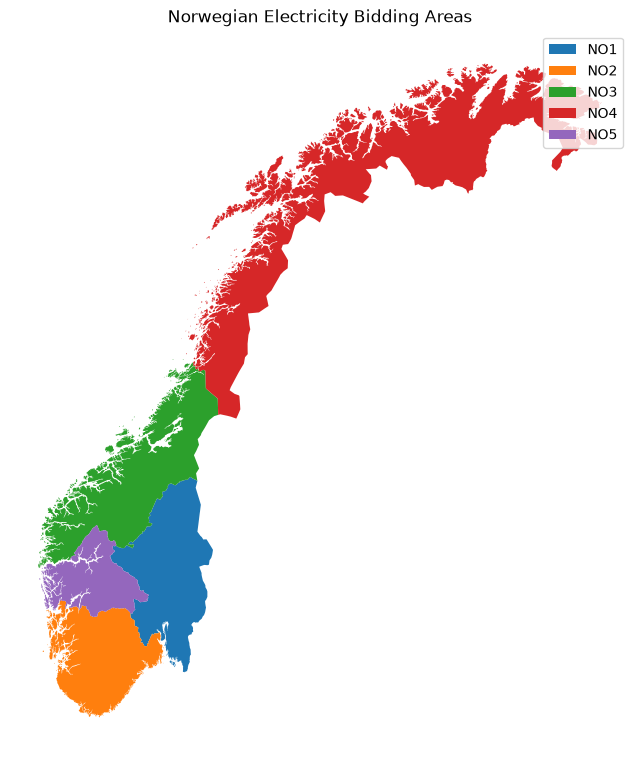

In [89]:
# Visualise the five Norwegian electricity bidding areas.
elspot_gdf.plot(
    column="ElSpotOmr",
    legend=True,
    figsize=(8, 10)
)

plt.title("Norwegian Electricity Bidding Areas")
plt.axis("off")
plt.show()

In [90]:
# Load the NVE regional polygons used to construct
# the broader weather regions for Magasinstatistikk.
region_path = shapefile_dir / "nve_regions.geojson"

region_gdf = gpd.read_file(region_path)

print("Columns:")
print(region_gdf.columns)

print("\nCRS:")
print(region_gdf.crs)

print("\nRegion codes:")
print(
    region_gdf[
        ["REGION", "REGIONNAVN"]
    ].sort_values("REGION")
)

Columns:
Index(['Shape.STArea()', 'Shape.STLength()', 'OBJECTID', 'REGION',
       'REGIONNAVN', 'POSTNUMMER', 'POSTSTED', 'BESØKSADR', 'ADRESSE',
       'geometry'],
      dtype='str')

CRS:
EPSG:4326

Region codes:
  REGION         REGIONNAVN
1     RM  Region Midt-Norge
2     RN        Region Nord
4     RS         Region Sør
0     RV        Region Vest
3     RØ         Region Øst


In [91]:
# Map the five NVE regions to the three broader regions
# required for weather sampling in the assignment.
weather_region_map = {
    "RS": "East",
    "RØ": "East",
    "RV": "West",
    "RM": "North",
    "RN": "North",
}

region_gdf["weather_region"] = (
    region_gdf["REGION"]
    .map(weather_region_map)
)

region_gdf[
    ["REGION", "REGIONNAVN", "weather_region"]
].sort_values("REGION")

,REGION,REGIONNAVN,weather_region
1,RM,Region Midt-Norge,North
2,RN,Region Nord,North
4,RS,Region Sør,East
0,RV,Region Vest,West
3,RØ,Region Øst,East


In [92]:
# Merge the five NVE regions into the three broader
# geographical regions used for weather sampling.
weather_regions_gdf = (
    region_gdf
    .dissolve(by="weather_region")
    .reset_index()
)

print(
    weather_regions_gdf[
        ["weather_region"]
    ]
)

  weather_region
0           East
1          North
2           West


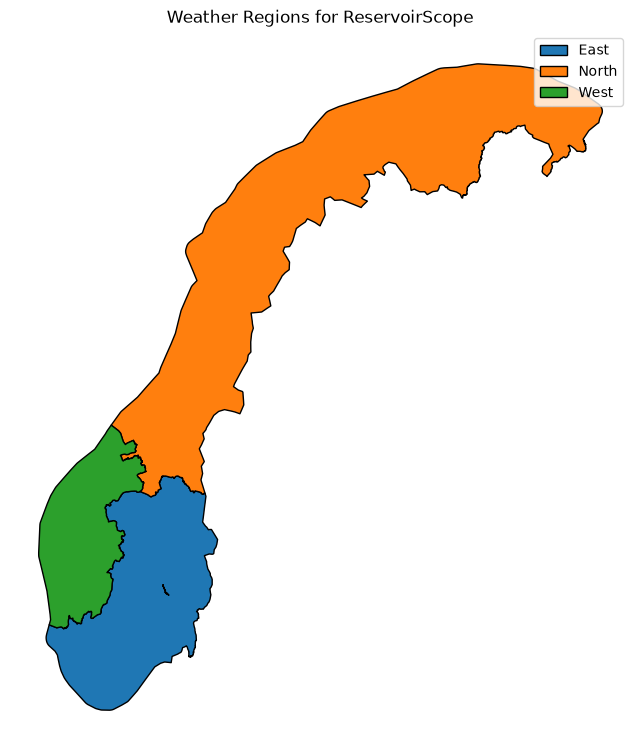

In [93]:
# Visualise the three broader weather regions
# before randomly sampling geographical locations.
weather_regions_gdf.plot(
    column="weather_region",
    legend=True,
    figsize=(8, 10),
    edgecolor="black"
)

plt.title("Weather Regions for ReservoirScope")
plt.axis("off")
plt.show()

In [94]:
# Project the weather-region polygons to ETRS89 / UTM zone 33N
# so random point sampling is performed in metres rather than degrees.
weather_regions_projected = (
    weather_regions_gdf
    .to_crs(epsg=25833)
)

print(weather_regions_projected.crs)

EPSG:25833


In [95]:
# Randomly sample a specified number of points inside a polygon.
# A fixed random seed is used so the sampling is reproducible.
import numpy as np
from shapely.geometry import Point


def sample_points_in_polygon(
    polygon,
    n_points=1000,
    random_seed=42
):
    rng = np.random.default_rng(random_seed)

    min_x, min_y, max_x, max_y = polygon.bounds

    points = []

    while len(points) < n_points:

        x = rng.uniform(min_x, max_x)
        y = rng.uniform(min_y, max_y)

        point = Point(x, y)

        if polygon.contains(point):
            points.append(point)

    return points

In [96]:
# Generate 1000 random locations inside each weather region.
sampled_regions = []

for index, row in weather_regions_projected.iterrows():

    region_name = row["weather_region"]

    points = sample_points_in_polygon(
        polygon=row.geometry,
        n_points=1000,
        random_seed=42 + index
    )

    region_points = gpd.GeoDataFrame(
        {
            "weather_region": [region_name] * len(points)
        },
        geometry=points,
        crs=weather_regions_projected.crs
    )

    sampled_regions.append(region_points)


sampled_points_gdf = pd.concat(
    sampled_regions,
    ignore_index=True
)

sampled_points_gdf = gpd.GeoDataFrame(
    sampled_points_gdf,
    geometry="geometry",
    crs=weather_regions_projected.crs
)

print(
    sampled_points_gdf[
        "weather_region"
    ].value_counts()
)

weather_region
East     1000
North    1000
West     1000
Name: count, dtype: int64


In [97]:
# Convert the sampled points back to WGS84 latitude/longitude
# because the Open-Meteo API expects geographic coordinates.
sampled_points_wgs84 = sampled_points_gdf.to_crs(epsg=4326)

sampled_points_wgs84["longitude"] = sampled_points_wgs84.geometry.x
sampled_points_wgs84["latitude"] = sampled_points_wgs84.geometry.y

sampled_points_wgs84.head()

,weather_region,geometry,longitude,latitude
0,East,POINT (10.98599 60.0238),10.985988,60.023804
1,East,POINT (11.59371 61.28368),11.593705,61.283683
2,East,POINT (10.65407 61.68348),10.654069,61.683476
3,East,POINT (9.55129 61.82063),9.551289,61.820628
4,East,POINT (8.32609 58.89564),8.326093,58.895640


In [98]:
# Confirm that each broader region still contains 1000 sampled locations.
print(
    sampled_points_wgs84[
        "weather_region"
    ].value_counts()
)

weather_region
East     1000
North    1000
West     1000
Name: count, dtype: int64


In [99]:
# Store the sampled longitude/latitude pairs by region
# so they can be passed to the weather-download function.
region_coordinates = {}

for region_name in sampled_points_wgs84["weather_region"].unique():

    region_df = sampled_points_wgs84[
        sampled_points_wgs84["weather_region"] == region_name
    ]

    region_coordinates[region_name] = list(
        zip(
            region_df["longitude"],
            region_df["latitude"]
        )
    )

for region_name, coordinates in region_coordinates.items():
    print(
        region_name,
        len(coordinates),
        coordinates[:3]
    )

East 1000 [(10.985987590196608, 60.02380353263818), (11.593705221333071, 61.283683204932906), (10.654069049999165, 61.68347561761898)]
North 1000 [(30.348252559331815, 70.08930308196052), (13.140701162557653, 64.95433442118961), (13.434418760652095, 67.52723155108127)]
West 1000 [(4.935151281911819, 60.51875560650939), (5.053026893490224, 60.85941179161045), (7.611579487513542, 62.178566831008496)]


In [100]:
# Save the sampled coordinates for reproducible reuse
# in the notebook and Streamlit application.
sampled_points_wgs84[
    [
        "weather_region",
        "longitude",
        "latitude"
    ]
].to_csv(
    "../data/weather_region_sample_points.csv",
    index=False
)

## Open-Meteo Historical Weather Data

Historical hourly weather data are retrieved from the Open-Meteo
Historical Weather API using the ERA5 reanalysis model.

The download function takes a weather-region identifier and a time
interval as input. It looks up the sampled longitude/latitude pairs for
that region and retrieves at least:

- temperature at 2 metres,
- precipitation.

The function is tested for the NO3-related weather region for 2024.

In [101]:
# Import requests for API communication and time for
# small pauses between batched Open-Meteo requests.
import requests
import time

In [102]:
# Download historical ERA5 weather data for sampled locations
# belonging to one selected weather region.
def download_weather_data(
    region_identifier,
    start_date,
    end_date,
    batch_size=50,
    coordinates_dict=None
):
    if coordinates_dict is None:
        coordinates_dict = region_coordinates

    if region_identifier not in coordinates_dict:
        raise ValueError(
            f"Unknown region: {region_identifier}. "
            f"Available regions: {list(coordinates_dict.keys())}"
        )

    coordinates = coordinates_dict[region_identifier]

    all_weather_data = []

    url = "https://archive-api.open-meteo.com/v1/archive"

    for start in range(
        0,
        len(coordinates),
        batch_size
    ):

        batch = coordinates[
            start:start + batch_size
        ]

        longitudes = [
            longitude
            for longitude, latitude in batch
        ]

        latitudes = [
            latitude
            for longitude, latitude in batch
        ]

        params = {
            "latitude": ",".join(map(str, latitudes)),
            "longitude": ",".join(map(str, longitudes)),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": [
                "temperature_2m",
                "precipitation"
            ],
            "models": "era5",
            "timezone": "UTC"
        }

        response = requests.get(
            url,
            params=params,
            timeout=120
        )

        response.raise_for_status()

        result = response.json()

        if isinstance(result, dict):
            result = [result]

        for location_result in result:

            hourly = location_result["hourly"]

            location_df = pd.DataFrame(
                {
                    "time": pd.to_datetime(
                        hourly["time"]
                    ),
                    "temperature_2m": hourly[
                        "temperature_2m"
                    ],
                    "precipitation": hourly[
                        "precipitation"
                    ],
                }
            )

            location_df["latitude"] = (
                location_result["latitude"]
            )

            location_df["longitude"] = (
                location_result["longitude"]
            )

            location_df["weather_region"] = (
                region_identifier
            )

            all_weather_data.append(
                location_df
            )

        print(
            f"Downloaded locations "
            f"{start + 1} to "
            f"{min(start + batch_size, len(coordinates))}"
        )

        time.sleep(0.2)

    weather_df = pd.concat(
        all_weather_data,
        ignore_index=True
    )

    return weather_df

In [103]:
# Temporarily keep only three East-region locations
# to verify that the Open-Meteo function works correctly.
test_region_coordinates = region_coordinates.copy()

test_region_coordinates["East"] = (
    region_coordinates["East"][:3]
)

In [104]:
# Use only three locations for the first API test.
test_region_coordinates = {
    "East": region_coordinates["East"][:3]
}

In [105]:
weather_test = download_weather_data(
    region_identifier="East",
    start_date="2024-01-01",
    end_date="2024-01-03",
    coordinates_dict=test_region_coordinates
)

print(weather_test.shape)

weather_test.head()

Downloaded locations 1 to 3
(216, 6)


,time,temperature_2m,precipitation,latitude,longitude,weather_region
0,2024-01-01 00:00:00,-4.6,0.4,60.0,11.0,East
1,2024-01-01 01:00:00,-4.7,0.4,60.0,11.0,East
2,2024-01-01 02:00:00,-4.8,0.5,60.0,11.0,East
3,2024-01-01 03:00:00,-4.9,0.5,60.0,11.0,East
4,2024-01-01 04:00:00,-5.0,0.5,60.0,11.0,East


In [106]:
# Project the electricity bidding-area polygons to a metric CRS
# before randomly sampling locations inside each area.
elspot_projected = (
    elspot_gdf
    .to_crs(epsg=25833)
)

print(elspot_projected.crs)

EPSG:25833


In [107]:
# Generate 1000 random locations inside each Norwegian
# electricity bidding area (NO1-NO5).
sampled_elspot_regions = []

for index, row in elspot_projected.iterrows():

    area_name = row["ElSpotOmr"]

    points = sample_points_in_polygon(
        polygon=row.geometry,
        n_points=1000,
        random_seed=100 + index
    )

    area_points = gpd.GeoDataFrame(
        {
            "region_identifier": [area_name] * len(points)
        },
        geometry=points,
        crs=elspot_projected.crs
    )

    sampled_elspot_regions.append(area_points)


sampled_elspot_gdf = pd.concat(
    sampled_elspot_regions,
    ignore_index=True
)

sampled_elspot_gdf = gpd.GeoDataFrame(
    sampled_elspot_gdf,
    geometry="geometry",
    crs=elspot_projected.crs
)

print(
    sampled_elspot_gdf[
        "region_identifier"
    ].value_counts().sort_index()
)

region_identifier
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
Name: count, dtype: int64


In [108]:
# Convert the sampled electricity-area locations to WGS84
# coordinates for use with the Open-Meteo API.
sampled_elspot_wgs84 = (
    sampled_elspot_gdf
    .to_crs(epsg=4326)
)

sampled_elspot_wgs84["longitude"] = (
    sampled_elspot_wgs84.geometry.x
)

sampled_elspot_wgs84["latitude"] = (
    sampled_elspot_wgs84.geometry.y
)

sampled_elspot_wgs84.head()

,region_identifier,geometry,longitude,latitude
0,NO2,POINT (10.37554 59.59263),10.375541,59.592625
1,NO2,POINT (8.9276 58.52119),8.927596,58.521193
2,NO2,POINT (8.42008 59.47022),8.420084,59.470222
3,NO2,POINT (8.276 59.34877),8.276000,59.348773
4,NO2,POINT (9.26224 59.29379),9.262242,59.293788


In [109]:
# Store the longitude/latitude pairs for each electricity area.
elspot_coordinates = {}

for area_name in sampled_elspot_wgs84["region_identifier"].unique():

    area_df = sampled_elspot_wgs84[
        sampled_elspot_wgs84["region_identifier"] == area_name
    ]

    elspot_coordinates[area_name] = list(
        zip(
            area_df["longitude"],
            area_df["latitude"]
        )
    )

for area_name, coordinates in elspot_coordinates.items():
    print(
        area_name,
        len(coordinates)
    )

NO2 1000
NO5 1000
NO1 1000
NO3 1000
NO4 1000


In [110]:
# Download historical ERA5 weather data for sampled locations
# belonging to one selected region identifier.
def download_weather_data(
    region_identifier,
    start_date,
    end_date,
    batch_size=50,
    coordinates_dict=None
):
    if coordinates_dict is None:
        coordinates_dict = elspot_coordinates

    if region_identifier not in coordinates_dict:
        raise ValueError(
            f"Unknown region: {region_identifier}. "
            f"Available regions: {list(coordinates_dict.keys())}"
        )

    coordinates = coordinates_dict[region_identifier]

    all_weather_data = []

    url = "https://archive-api.open-meteo.com/v1/archive"

    for start in range(
        0,
        len(coordinates),
        batch_size
    ):
        batch = coordinates[
            start:start + batch_size
        ]

        longitudes = [
            longitude
            for longitude, latitude in batch
        ]

        latitudes = [
            latitude
            for longitude, latitude in batch
        ]

        params = {
            "latitude": ",".join(
                map(str, latitudes)
            ),
            "longitude": ",".join(
                map(str, longitudes)
            ),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": [
                "temperature_2m",
                "precipitation"
            ],
            "models": "era5",
            "timezone": "UTC"
        }

        response = requests.get(
            url,
            params=params,
            timeout=120
        )

        response.raise_for_status()

        result = response.json()

        if isinstance(result, dict):
            result = [result]

        for location_result in result:
            hourly = location_result["hourly"]

            location_df = pd.DataFrame(
                {
                    "time": pd.to_datetime(
                        hourly["time"]
                    ),
                    "temperature_2m": hourly[
                        "temperature_2m"
                    ],
                    "precipitation": hourly[
                        "precipitation"
                    ],
                }
            )

            location_df["latitude"] = (
                location_result["latitude"]
            )

            location_df["longitude"] = (
                location_result["longitude"]
            )

            location_df["region_identifier"] = (
                region_identifier
            )

            all_weather_data.append(
                location_df
            )

        print(
            f"Downloaded locations "
            f"{start + 1} to "
            f"{min(start + batch_size, len(coordinates))}"
        )

        time.sleep(0.2)

    return pd.concat(
        all_weather_data,
        ignore_index=True
    )

In [111]:
# Test the NO3 workflow on three locations
# before downloading the complete 2024 dataset.
test_no3_coordinates = {
    "NO3": elspot_coordinates["NO3"][:3]
}

no3_test = download_weather_data(
    region_identifier="NO3",
    start_date="2024-01-01",
    end_date="2024-01-03",
    coordinates_dict=test_no3_coordinates
)

print(no3_test.shape)

no3_test.head()

Downloaded locations 1 to 3
(216, 6)


,time,temperature_2m,precipitation,latitude,longitude,region_identifier
0,2024-01-01 00:00:00,-5.8,0.0,62.0,7.0,NO3
1,2024-01-01 01:00:00,-6.0,0.0,62.0,7.0,NO3
2,2024-01-01 02:00:00,-6.2,0.0,62.0,7.0,NO3
3,2024-01-01 03:00:00,-6.3,0.0,62.0,7.0,NO3
4,2024-01-01 04:00:00,-6.0,0.0,62.0,7.0,NO3


In [115]:
# Download historical ERA5 weather data for sampled locations
# while handling Open-Meteo rate limits with retries and backoff.
def download_weather_data(
    region_identifier,
    start_date,
    end_date,
    batch_size=10,
    coordinates_dict=None,
    max_retries=6
):
    if coordinates_dict is None:
        coordinates_dict = elspot_coordinates

    if region_identifier not in coordinates_dict:
        raise ValueError(
            f"Unknown region: {region_identifier}. "
            f"Available regions: {list(coordinates_dict.keys())}"
        )

    coordinates = coordinates_dict[region_identifier]

    all_weather_data = []

    url = "https://archive-api.open-meteo.com/v1/archive"

    for start in range(
        0,
        len(coordinates),
        batch_size
    ):
        batch = coordinates[
            start:start + batch_size
        ]

        longitudes = [
            longitude
            for longitude, latitude in batch
        ]

        latitudes = [
            latitude
            for longitude, latitude in batch
        ]

        params = {
            "latitude": ",".join(map(str, latitudes)),
            "longitude": ",".join(map(str, longitudes)),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": [
                "temperature_2m",
                "precipitation"
            ],
            "models": "era5",
            "timezone": "UTC"
        }

        for attempt in range(max_retries):

            response = requests.get(
                url,
                params=params,
                timeout=120
            )

            if response.status_code == 429:

                wait_seconds = 5 * (attempt + 1)

                print(
                    f"Rate limit reached. "
                    f"Retrying in {wait_seconds} seconds..."
                )

                time.sleep(wait_seconds)

                continue

            response.raise_for_status()

            break

        else:
            raise RuntimeError(
                "Open-Meteo rate limit persisted after retries."
            )

        result = response.json()

        if isinstance(result, dict):
            result = [result]

        for location_result in result:

            hourly = location_result["hourly"]

            location_df = pd.DataFrame(
                {
                    "time": pd.to_datetime(
                        hourly["time"]
                    ),
                    "temperature_2m": hourly[
                        "temperature_2m"
                    ],
                    "precipitation": hourly[
                        "precipitation"
                    ],
                }
            )

            location_df["latitude"] = (
                location_result["latitude"]
            )

            location_df["longitude"] = (
                location_result["longitude"]
            )

            location_df["region_identifier"] = (
                region_identifier
            )

            all_weather_data.append(
                location_df
            )

        print(
            f"Downloaded locations "
            f"{start + 1} to "
            f"{min(start + batch_size, len(coordinates))}"
        )

        time.sleep(2)

    return pd.concat(
        all_weather_data,
        ignore_index=True
    )

In [118]:
test_no3_20 = {
    "NO3": elspot_coordinates["NO3"][:20]
}

no3_test_2024 = download_weather_data(
    region_identifier="NO3",
    start_date="2024-01-01",
    end_date="2024-12-31",
    batch_size=5,
    coordinates_dict=test_no3_20
)

print(no3_test_2024.shape)

Rate limit reached. Retrying in 5 seconds...
Rate limit reached. Retrying in 10 seconds...
Rate limit reached. Retrying in 15 seconds...
Rate limit reached. Retrying in 20 seconds...
Rate limit reached. Retrying in 25 seconds...
Rate limit reached. Retrying in 30 seconds...


RuntimeError: Open-Meteo rate limit persisted after retries.

In [ ]:
# Download NO3 weather data one month at a time
# and save each monthly result immediately.
from calendar import monthrange

monthly_files = []

for month in range(1, 13):

    start_date = f"2024-{month:02d}-01"

    last_day = monthrange(
        2024,
        month
    )[1]

    end_date = f"2024-{month:02d}-{last_day:02d}"

    print(
        f"\nDownloading {start_date} to {end_date}"
    )

    month_df = download_weather_data(
        region_identifier="NO3",
        start_date=start_date,
        end_date=end_date,
        batch_size=5,
        coordinates_dict=elspot_coordinates
    )

    file_path = (
        f"../data/no3_weather_2024_{month:02d}.parquet"
    )

    month_df.to_parquet(
        file_path,
        index=False
    )

    monthly_files.append(
        file_path
    )

    print(
        f"Saved month {month:02d}:",
        month_df.shape
    )

In [119]:
from pathlib import Path

saved_files = sorted(
    Path("../data").glob("no3_weather_2024_*.parquet")
)

for file in saved_files:
    print(file.name)

no3_weather_2024_01.parquet
no3_weather_2024_02.parquet
no3_weather_2024_03.parquet
no3_weather_2024_04.parquet


In [120]:
print("Saved months:", len(saved_files))

Saved months: 4


In [121]:
# Resume the NO3 monthly download and skip months
# that have already been saved successfully.
from pathlib import Path
from calendar import monthrange

data_dir = Path("../data")

for month in range(1, 13):

    file_path = (
        data_dir
        / f"no3_weather_2024_{month:02d}.parquet"
    )

    # Skip months that were already downloaded.
    if file_path.exists():
        print(
            f"Month {month:02d} already exists. Skipping."
        )
        continue

    start_date = f"2024-{month:02d}-01"

    last_day = monthrange(
        2024,
        month
    )[1]

    end_date = (
        f"2024-{month:02d}-{last_day:02d}"
    )

    print(
        f"\nDownloading {start_date} to {end_date}"
    )

    try:
        month_df = download_weather_data(
            region_identifier="NO3",
            start_date=start_date,
            end_date=end_date,
            batch_size=5,
            coordinates_dict=elspot_coordinates
        )

        month_df.to_parquet(
            file_path,
            index=False
        )

        print(
            f"Saved month {month:02d}:",
            month_df.shape
        )

    except Exception as error:

        print(
            f"Month {month:02d} failed:"
        )

        print(error)

        break

Month 01 already exists. Skipping.
Month 02 already exists. Skipping.
Month 03 already exists. Skipping.
Month 04 already exists. Skipping.

Rate limit reached. Retrying in 5 seconds...
Rate limit reached. Retrying in 10 seconds...
Rate limit reached. Retrying in 15 seconds...
Rate limit reached. Retrying in 20 seconds...
Rate limit reached. Retrying in 25 seconds...
Rate limit reached. Retrying in 30 seconds...
Month 05 failed:
Open-Meteo rate limit persisted after retries.


In [122]:
from pathlib import Path
import pandas as pd

saved_files = sorted(
    Path("../data").glob("no3_weather_2024_*.parquet")
)

partial_weather_df = pd.concat(
    [
        pd.read_parquet(file)
        for file in saved_files
    ],
    ignore_index=True
)

print("Months loaded:", len(saved_files))
print("Rows:", len(partial_weather_df))

partial_weather_df.head()

Months loaded: 4
Rows: 2904000


,time,temperature_2m,precipitation,latitude,longitude,region_identifier
0,2024-01-01 00:00:00,-5.8,0.0,62.0,7.0,NO3
1,2024-01-01 01:00:00,-6.0,0.0,62.0,7.0,NO3
2,2024-01-01 02:00:00,-6.2,0.0,62.0,7.0,NO3
3,2024-01-01 03:00:00,-6.3,0.0,62.0,7.0,NO3
4,2024-01-01 04:00:00,-6.0,0.0,62.0,7.0,NO3


In [123]:
print(
    "First timestamp:",
    partial_weather_df["time"].min()
)

print(
    "Last timestamp:",
    partial_weather_df["time"].max()
)

First timestamp: 2024-01-01 00:00:00
Last timestamp: 2024-04-30 23:00:00


In [124]:
# Calculate the average precipitation across all sampled NO3 locations
# for each hourly timestamp.
avg_precipitation = (
    partial_weather_df
    .groupby("time", as_index=False)["precipitation"]
    .mean()
    .sort_values("time")
)

avg_precipitation.head()

,time,precipitation
0,2024-01-01 00:00:00,0.0061
1,2024-01-01 01:00:00,0.0051
2,2024-01-01 02:00:00,0.0051
3,2024-01-01 03:00:00,0.0051
4,2024-01-01 04:00:00,0.0051


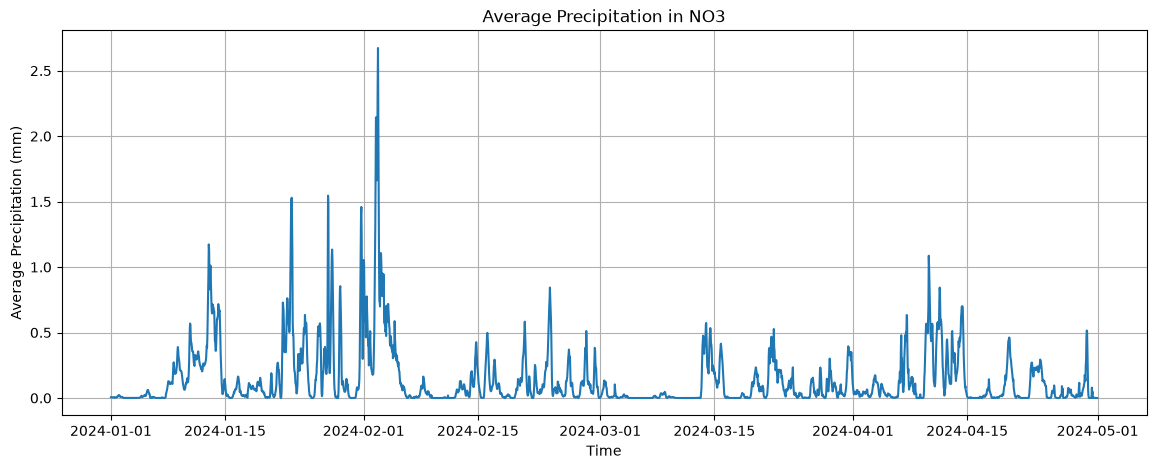

In [125]:
# Plot the average hourly precipitation over time.
plt.figure(figsize=(14, 5))

plt.plot(
    avg_precipitation["time"],
    avg_precipitation["precipitation"]
)

plt.title("Average Precipitation in NO3")
plt.xlabel("Time")
plt.ylabel("Average Precipitation (mm)")
plt.grid(True)

plt.show()

In [126]:
# Detect precipitation outliers using DCT high-pass filtering
# and robust Statistical Process Control boundaries.
import numpy as np
from scipy.fft import dct, idct


def precipitation_spc_analysis(
    weather_df,
    frequency_cutoff=50,
    n_std=3
):
    hourly_avg = (
        weather_df
        .groupby("time", as_index=False)["precipitation"]
        .mean()
        .sort_values("time")
    )

    values = hourly_avg["precipitation"].to_numpy()

    # Transform the precipitation series into the frequency domain.
    coefficients = dct(
        values,
        norm="ortho"
    )

    # Remove the low-frequency seasonal component.
    high_pass_coefficients = coefficients.copy()
    high_pass_coefficients[:frequency_cutoff] = 0

    satv = idct(
        high_pass_coefficients,
        norm="ortho"
    )

    # Robust centre and spread using median and MAD.
    centre = np.median(satv)

    mad = np.median(
        np.abs(satv - centre)
    )

    robust_std = 1.4826 * mad

    lower_limit = centre - n_std * robust_std
    upper_limit = centre + n_std * robust_std

    outlier_mask = (
        (satv < lower_limit)
        |
        (satv > upper_limit)
    )

    outliers = hourly_avg.loc[
        outlier_mask
    ].copy()

    # Plot original precipitation only.
    fig, ax = plt.subplots(
        figsize=(14, 5)
    )

    ax.plot(
        hourly_avg["time"],
        hourly_avg["precipitation"],
        label="Average precipitation"
    )

    ax.scatter(
        outliers["time"],
        outliers["precipitation"],
        label="Outliers",
        zorder=3
    )

    ax.set_title(
        "Average NO3 Precipitation with SPC Outliers"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Average Precipitation (mm)")
    ax.grid(True)
    ax.legend()

    summary = {
        "number_of_observations": len(hourly_avg),
        "number_of_outliers": int(outlier_mask.sum()),
        "outlier_percentage": (
            float(outlier_mask.mean() * 100)
        ),
        "frequency_cutoff": frequency_cutoff,
        "n_std": n_std,
        "lower_satv_limit": lower_limit,
        "upper_satv_limit": upper_limit
    }

    return fig, outliers, summary

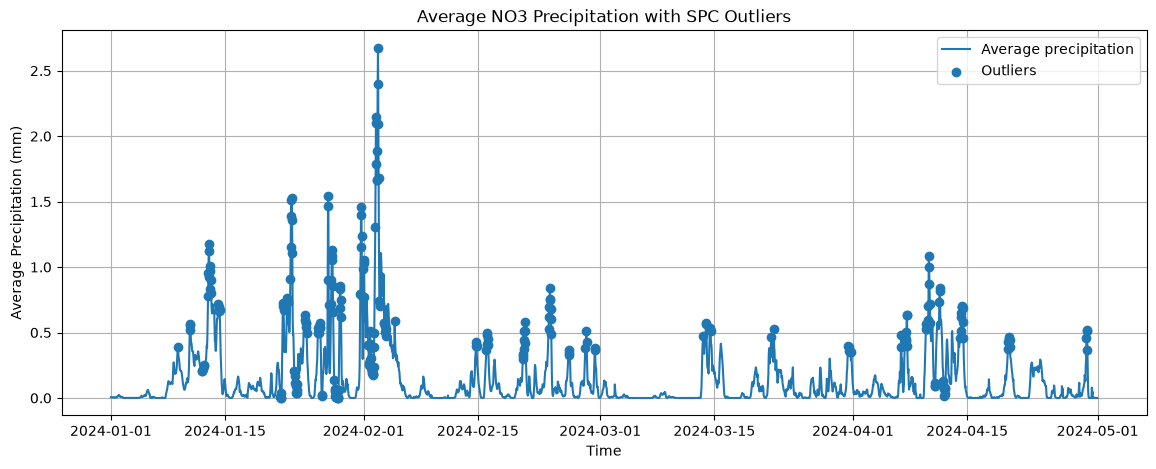

{'number_of_observations': 2904, 'number_of_outliers': 248, 'outlier_percentage': 8.539944903581267, 'frequency_cutoff': 50, 'n_std': 3, 'lower_satv_limit': np.float64(-0.2673086204204497), 'upper_satv_limit': np.float64(0.23196383804352214)}


,time,precipitation
197,2024-01-09 05:00:00,0.3891
232,2024-01-10 16:00:00,0.5183
233,2024-01-10 17:00:00,0.5686
234,2024-01-10 18:00:00,0.5556
268,2024-01-12 04:00:00,0.2032


In [127]:
precip_fig, precip_outliers, precip_summary = (
    precipitation_spc_analysis(
        partial_weather_df,
        frequency_cutoff=50,
        n_std=3
    )
)

plt.show()

print(precip_summary)

precip_outliers.head()

In [128]:
# Detect temperature anomalies using the Local Outlier Factor method.
# The contamination parameter controls the expected proportion of anomalies.
from sklearn.neighbors import LocalOutlierFactor


def temperature_lof_analysis(
    weather_df,
    contamination=0.01
):
    hourly_avg = (
        weather_df
        .groupby("time", as_index=False)["temperature_2m"]
        .mean()
        .sort_values("time")
    )

    values = hourly_avg[
        ["temperature_2m"]
    ].to_numpy()

    lof = LocalOutlierFactor(
        contamination=contamination
    )

    labels = lof.fit_predict(values)

    anomaly_mask = labels == -1

    anomalies = hourly_avg.loc[
        anomaly_mask
    ].copy()

    fig, ax = plt.subplots(
        figsize=(14, 5)
    )

    ax.plot(
        hourly_avg["time"],
        hourly_avg["temperature_2m"],
        label="Average temperature"
    )

    ax.scatter(
        anomalies["time"],
        anomalies["temperature_2m"],
        label="Anomalies",
        zorder=3
    )

    ax.set_title(
        "Average NO3 Temperature with LOF Anomalies"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Average Temperature (°C)")
    ax.grid(True)
    ax.legend()

    summary = {
        "number_of_observations": len(hourly_avg),
        "number_of_anomalies": int(anomaly_mask.sum()),
        "anomaly_percentage": float(
            anomaly_mask.mean() * 100
        ),
        "contamination": contamination
    }

    return fig, anomalies, summary

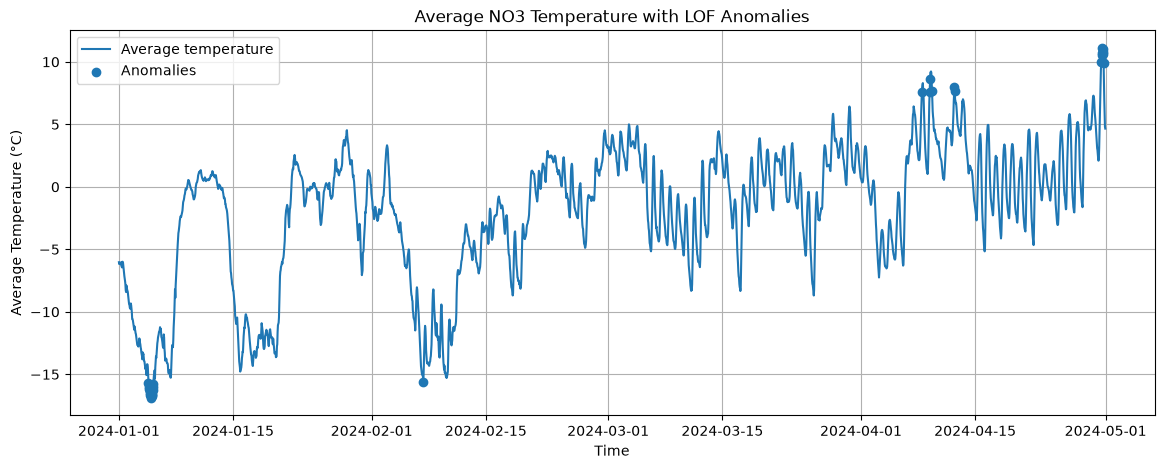

{'number_of_observations': 2904, 'number_of_anomalies': 30, 'anomaly_percentage': 1.0330578512396695, 'contamination': 0.01}


,time,temperature_2m
87,2024-01-04 15:00:00,-15.6766
88,2024-01-04 16:00:00,-16.0356
89,2024-01-04 17:00:00,-16.2028
90,2024-01-04 18:00:00,-16.3634
91,2024-01-04 19:00:00,-16.4709


In [129]:
temperature_fig, temperature_anomalies, temperature_summary = (
    temperature_lof_analysis(
        partial_weather_df,
        contamination=0.01
    )
)

plt.show()

print(temperature_summary)

temperature_anomalies.head()

In [130]:
# Load reservoir statistics directly from the NVE API
# for the STL and spectrogram analyses.
import requests

nve_url = (
    "https://biapi.nve.no/magasinstatistikk/api/"
    "Magasinstatistikk/HentOffentligData"
)

response = requests.get(
    nve_url,
    timeout=30
)

response.raise_for_status()

reservoir_df = pd.DataFrame(
    response.json()
)

In [131]:
# Rename the NVE variables needed for reservoir analysis.
reservoir_df = reservoir_df.rename(
    columns={
        "dato_Id": "date",
        "omrType": "area_type",
        "omrnr": "area_number",
        "fyllingsgrad": "fill_level"
    }
)

reservoir_df["date"] = pd.to_datetime(
    reservoir_df["date"]
)

reservoir_df.head()

,date,area_type,area_number,iso_aar,iso_uke,fill_level,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [132]:
# Select the national reservoir filling-level series.
national_fill = (
    reservoir_df[
        (reservoir_df["area_type"] == "NO")
        &
        (reservoir_df["area_number"] == 0)
    ][["date", "fill_level"]]
    .sort_values("date")
    .dropna()
)

national_fill.head()

,date,fill_level
9693,1995-01-08,0.607988
9746,1995-01-15,0.582088
9536,1995-01-22,0.562121
9719,1995-01-29,0.534222
9766,1995-02-05,0.506221


In [133]:
# Perform STL decomposition on reservoir filling level.
# Seasonal and trend smoother lengths can be adjusted,
# and robust fitting can be enabled or disabled.
from statsmodels.tsa.seasonal import STL


def reservoir_stl_analysis(
    reservoir_data,
    seasonal=53,
    trend=105,
    robust=True
):
    series = (
        reservoir_data
        .set_index("date")["fill_level"]
        .sort_index()
    )

    stl = STL(
        series,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    fig = result.plot()

    fig.set_size_inches(
        12,
        8
    )

    fig.suptitle(
        "STL Decomposition of National Reservoir Filling Level",
        y=1.02
    )

    return fig, result

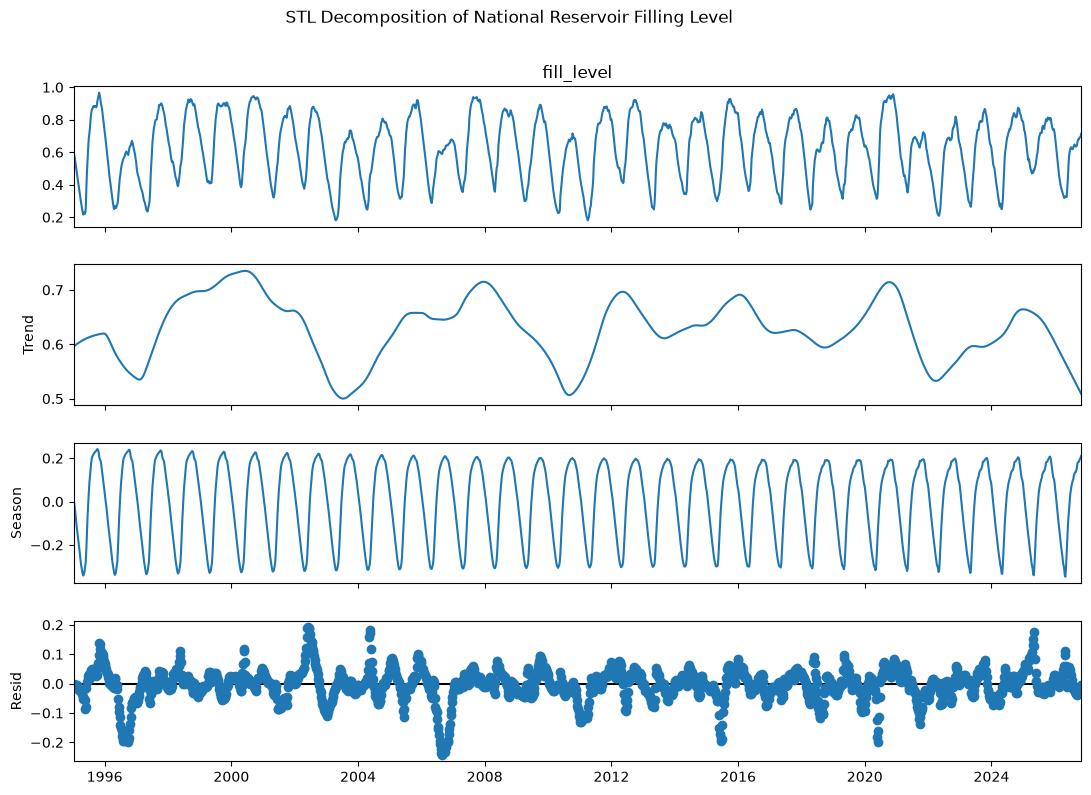

In [134]:
stl_fig, stl_result = reservoir_stl_analysis(
    national_fill,
    seasonal=53,
    trend=105,
    robust=True
)

plt.show()

In [135]:
# Import the spectrogram function for time-frequency analysis.
from scipy.signal import spectrogram

In [136]:
# Create a spectrogram of reservoir filling level.
# Window length and overlap can be adjusted.
def reservoir_spectrogram(
    reservoir_data,
    window_length=104,
    window_overlap=52
):
    series = (
        reservoir_data
        .set_index("date")["fill_level"]
        .sort_index()
    )

    values = series.to_numpy()

    frequencies, times, power = spectrogram(
        values,
        fs=1,
        nperseg=window_length,
        noverlap=window_overlap
    )

    fig, ax = plt.subplots(
        figsize=(12, 6)
    )

    mesh = ax.pcolormesh(
        times,
        frequencies,
        power,
        shading="auto"
    )

    ax.set_title(
        "Spectrogram of National Reservoir Filling Level"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency (cycles per week)")

    fig.colorbar(
        mesh,
        ax=ax,
        label="Power"
    )

    return fig, {
        "frequencies": frequencies,
        "times": times,
        "power": power
    }

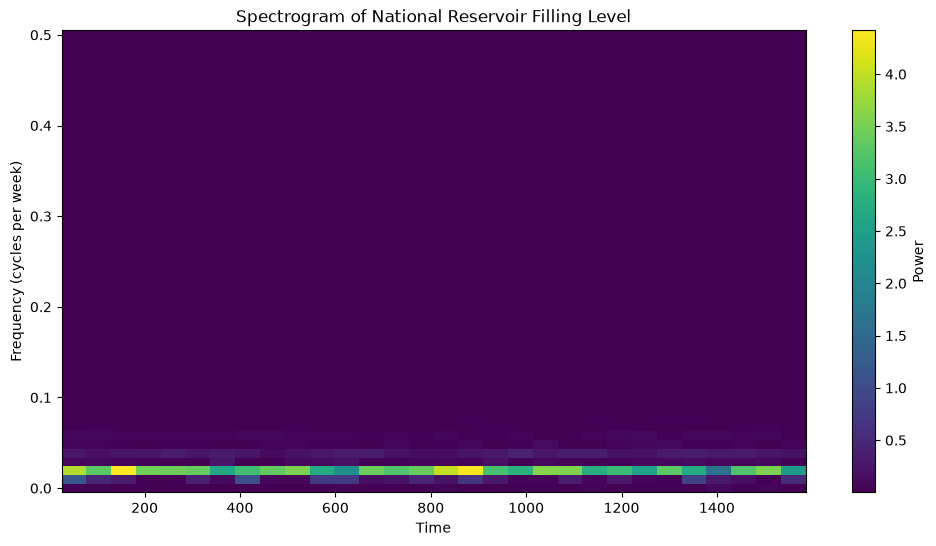

In [137]:
spectrogram_fig, spectrogram_result = (
    reservoir_spectrogram(
        national_fill,
        window_length=104,
        window_overlap=52
    )
)

plt.show()